In [1]:
!pip install tensorflow numpy pandas matplotlib seaborn opencv-python scikit-learn pillow
print("okay done")

okay done


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

print("Libraries imported successfully")
print("okay done")

Libraries imported successfully
okay done


In [3]:
dataset_path = "dataset"

import zipfile
import os

zip_path = r"C:\Users\YUVARANI\Downloads\Dataset.zip"
extract_path = r"C:\Users\YUVARANI\Downloads\Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
print(os.listdir(extract_path))

['Dataset']


In [5]:
import os

dataset_path = r"C:\Users\YUVARANI\Downloads\Dataset"

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print(folder, ":", len(os.listdir(folder_path)), "images")

Dataset : 15 images


In [6]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, file))

print("Total images:", len(image_paths))

Total images: 19012


In [7]:
data = []

for path in image_paths:
    label = os.path.basename(os.path.dirname(path))

    data.append({
        "image_path": path,
        "label": label
    })

df = pd.DataFrame(data)

print(df.head())
print("\nClasses:")
print(df["label"].value_counts())

                                          image_path  \
0  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
1  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
2  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
3  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
4  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   

                           label  
0  Pepper__bell___Bacterial_spot  
1  Pepper__bell___Bacterial_spot  
2  Pepper__bell___Bacterial_spot  
3  Pepper__bell___Bacterial_spot  
4  Pepper__bell___Bacterial_spot  

Classes:
label
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Tomato_Early_blight  

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate image paths:")
print(df["image_path"].duplicated().sum())

Missing values:
image_path    0
label         0
dtype: int64

Duplicate image paths:
0


In [11]:
valid_images = []
corrupted_images = []

for path in image_paths:
    try:
        img = cv2.imread(path)

        if img is not None:
            valid_images.append(path)
        else:
            corrupted_images.append(path)

    except:
        corrupted_images.append(path)

print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

Valid images: 19012
Corrupted images: 0


In [12]:
df = df[df["image_path"].isin(valid_images)].reset_index(drop=True)

print("Final image count:", len(df))

Final image count: 19012


In [16]:
widths = []
heights = []

for path in df["image_path"]:
    img = cv2.imread(path)

    h, w = img.shape[:2]

    widths.append(w)
    heights.append(h)

df["width"] = widths
df["height"] = heights

print(df[["width", "height"]].describe())

         width   height
count  19012.0  19012.0
mean     256.0    256.0
std        0.0      0.0
min      256.0    256.0
25%      256.0    256.0
50%      256.0    256.0
75%      256.0    256.0
max      256.0    256.0


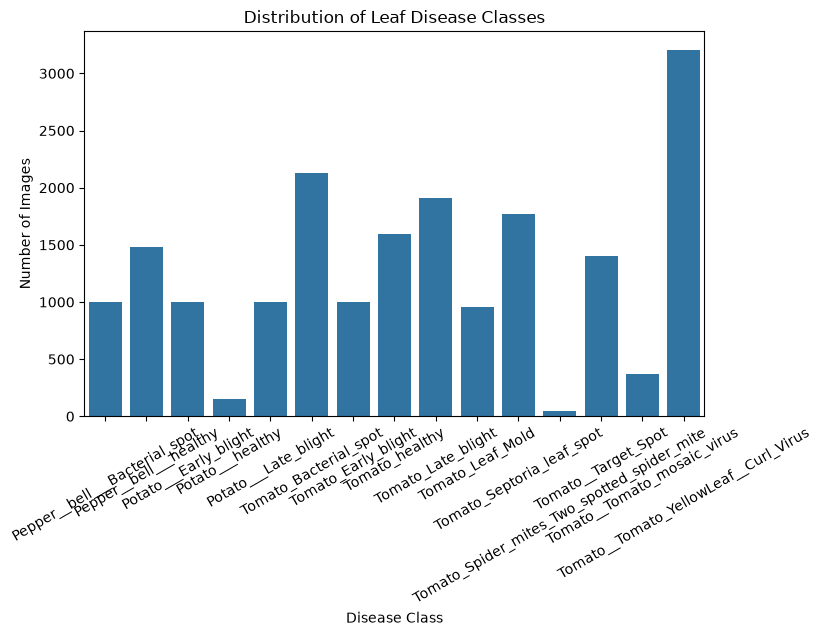

In [18]:
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Leaf Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

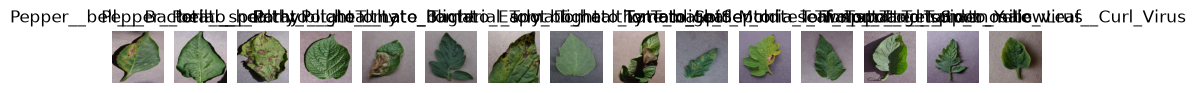

In [19]:
classes = df["label"].unique()

plt.figure(figsize=(12, 5))

for i, class_name in enumerate(classes):
    sample_path = df[df["label"] == class_name]["image_path"].iloc[0]

    img = cv2.imread(sample_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, len(classes), i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.show()

In [22]:
brightness = []
sharpness = []
red_values = []
green_values = []
blue_values = []
hue_values = []
saturation_values = []

for path in df["image_path"]:
    img = cv2.imread(path)
    img = cv2.resize(img, (128, 128))

    brightness.append(np.mean(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)))
    sharpness.append(cv2.Laplacian(img, cv2.CV_64F).var())

    b, g, r = cv2.split(img)

    blue_values.append(np.mean(b))
    green_values.append(np.mean(g))
    red_values.append(np.mean(r))

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    hue_values.append(np.mean(hsv[:, :, 0]))
    saturation_values.append(np.mean(hsv[:, :, 1]))

df["brightness"] = brightness
df["sharpness"] = sharpness
df["red"] = red_values
df["green"] = green_values
df["blue"] = blue_values
df["hue"] = hue_values
df["saturation"] = saturation_values

print(df.head())

                                          image_path  \
0  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
1  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
2  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
3  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   
4  C:\Users\YUVARANI\Downloads\Dataset\Dataset\Pe...   

                           label  width  height  brightness    sharpness  \
0  Pepper__bell___Bacterial_spot    256     256  123.489868  1901.751626   
1  Pepper__bell___Bacterial_spot    256     256  103.239441  3181.471104   
2  Pepper__bell___Bacterial_spot    256     256  131.141907  2336.646112   
3  Pepper__bell___Bacterial_spot    256     256  122.880005  5015.900687   
4  Pepper__bell___Bacterial_spot    256     256   98.102417  2856.962263   

          red       green        blue        hue  saturation  
0  124.596497  125.759338  108.611511  91.772644   61.977600  
1   99.945984  106.374878   95.781311  89.080627   67.505188  
2  128.994202  13

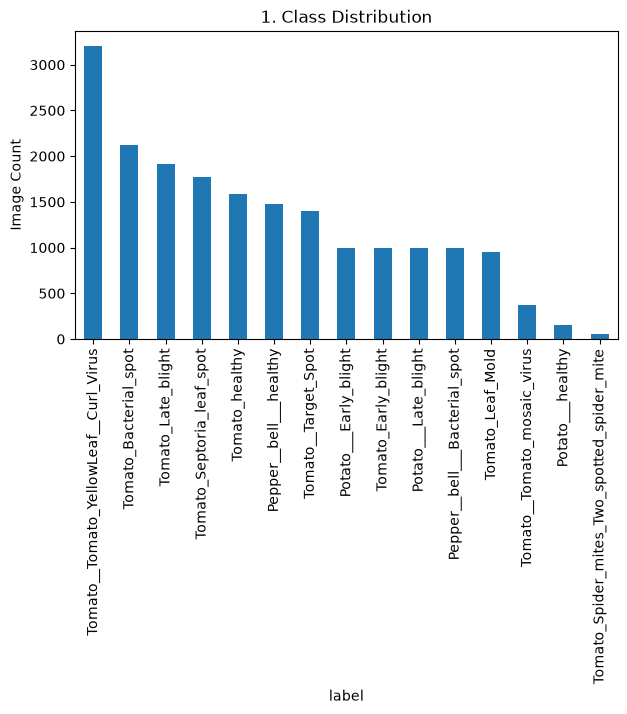

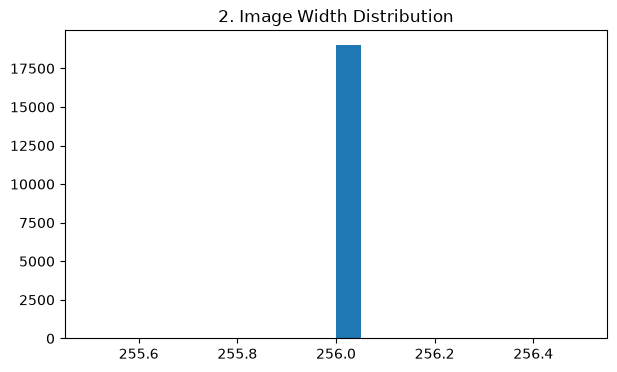

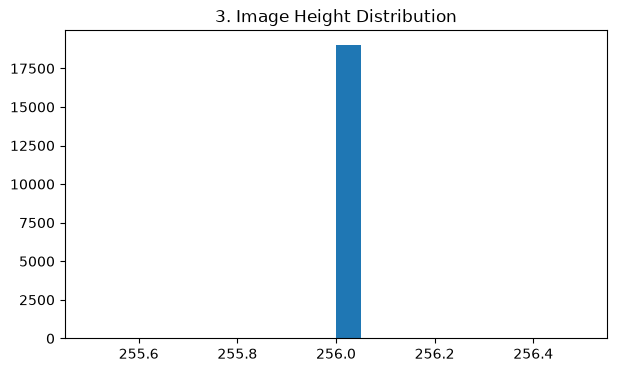

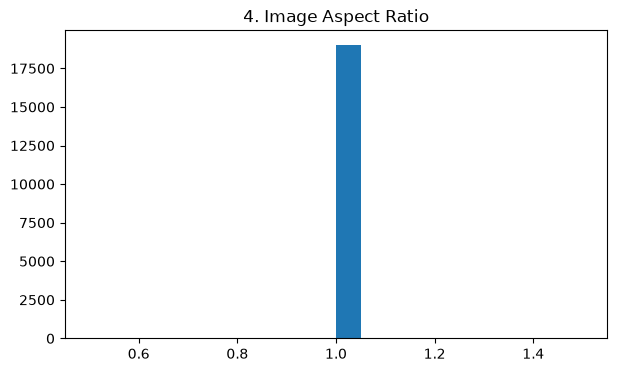

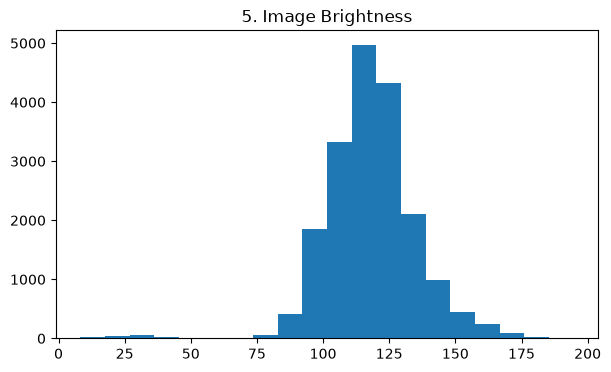

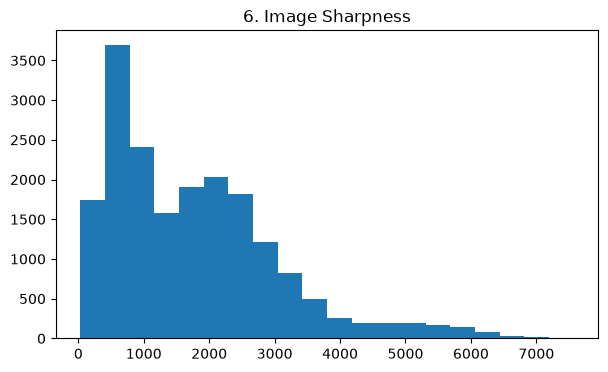

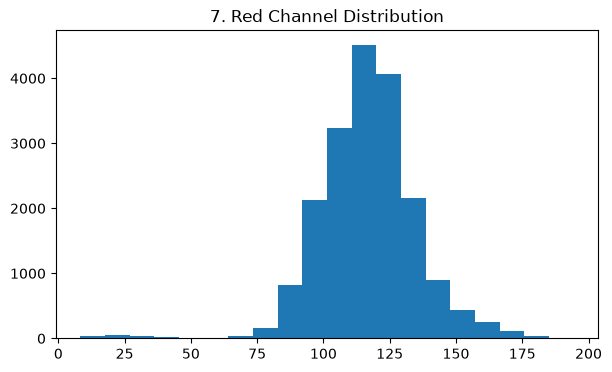

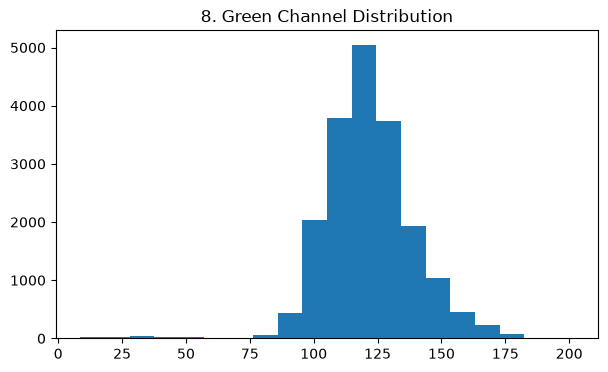

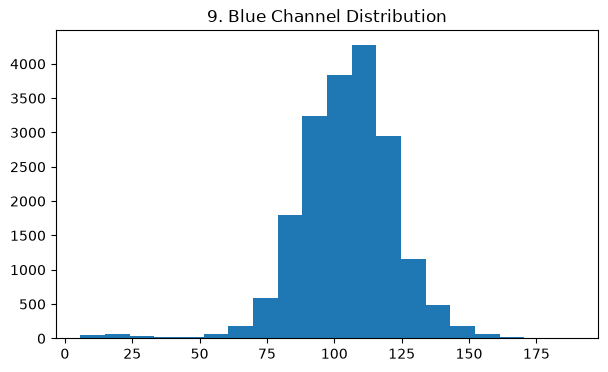

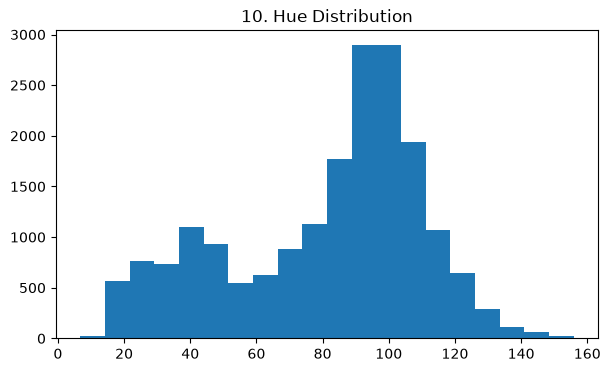

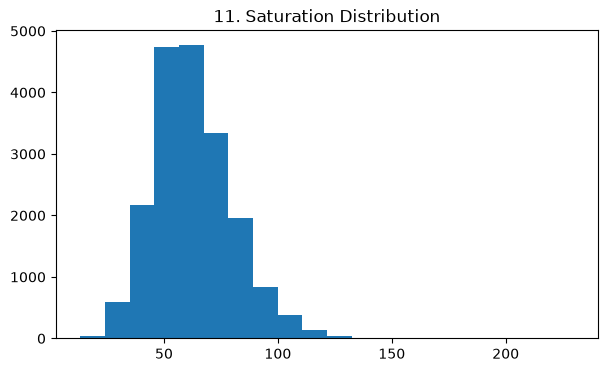

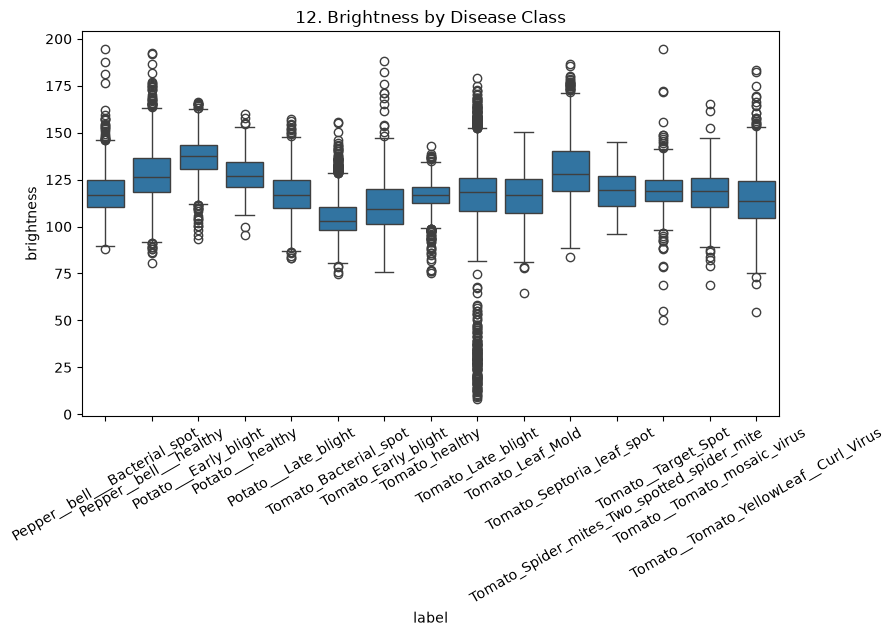

In [23]:
# Chart 1: Class distribution
plt.figure(figsize=(7, 4))
df["label"].value_counts().plot(kind="bar")
plt.title("1. Class Distribution")
plt.ylabel("Image Count")
plt.show()

# Chart 2: Image width
plt.figure(figsize=(7, 4))
plt.hist(df["width"], bins=20)
plt.title("2. Image Width Distribution")
plt.show()

# Chart 3: Image height
plt.figure(figsize=(7, 4))
plt.hist(df["height"], bins=20)
plt.title("3. Image Height Distribution")
plt.show()

# Chart 4: Image aspect ratio
plt.figure(figsize=(7, 4))
plt.hist(df["width"] / df["height"], bins=20)
plt.title("4. Image Aspect Ratio")
plt.show()

# Chart 5: Brightness distribution
plt.figure(figsize=(7, 4))
plt.hist(df["brightness"], bins=20)
plt.title("5. Image Brightness")
plt.show()

# Chart 6: Sharpness distribution
plt.figure(figsize=(7, 4))
plt.hist(df["sharpness"], bins=20)
plt.title("6. Image Sharpness")
plt.show()

# Chart 7: Red channel
plt.figure(figsize=(7, 4))
plt.hist(df["red"], bins=20)
plt.title("7. Red Channel Distribution")
plt.show()

# Chart 8: Green channel
plt.figure(figsize=(7, 4))
plt.hist(df["green"], bins=20)
plt.title("8. Green Channel Distribution")
plt.show()

# Chart 9: Blue channel
plt.figure(figsize=(7, 4))
plt.hist(df["blue"], bins=20)
plt.title("9. Blue Channel Distribution")
plt.show()

# Chart 10: Hue distribution
plt.figure(figsize=(7, 4))
plt.hist(df["hue"], bins=20)
plt.title("10. Hue Distribution")
plt.show()

# Chart 11: Saturation distribution
plt.figure(figsize=(7, 4))
plt.hist(df["saturation"], bins=20)
plt.title("11. Saturation Distribution")
plt.show()

# Chart 12: Brightness by class
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="label", y="brightness")
plt.title("12. Brightness by Disease Class")
plt.xticks(rotation=30)
plt.show()

In [24]:
IMG_SIZE = 224

X_images = []
y_labels = []

for _, row in df.iterrows():

    img = cv2.imread(row["image_path"])

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

    X_images.append(img)
    y_labels.append(row["label"])

X_images = np.array(X_images)
y_labels = np.array(y_labels)

print("Image shape:", X_images.shape)
print("Labels shape:", y_labels.shape)

Image shape: (19012, 224, 224, 3)
Labels shape: (19012,)


In [25]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y_labels)

print("Disease classes:", label_encoder.classes_)
print("Encoded labels:", np.unique(y))

Disease classes: ['Pepper__bell___Bacterial_spot' 'Pepper__bell___healthy'
 'Potato___Early_blight' 'Potato___Late_blight' 'Potato___healthy'
 'Tomato_Bacterial_spot' 'Tomato_Early_blight' 'Tomato_Late_blight'
 'Tomato_Leaf_Mold' 'Tomato_Septoria_leaf_spot'
 'Tomato_Spider_mites_Two_spotted_spider_mite' 'Tomato__Target_Spot'
 'Tomato__Tomato_YellowLeaf__Curl_Virus' 'Tomato__Tomato_mosaic_virus'
 'Tomato_healthy']
Encoded labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_images,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 15209
Testing images: 3803


In [28]:
def extract_hsv_features(images):

    features = []

    for img in images:

        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        hist = cv2.calcHist(
            [hsv],
            [0, 1, 2],
            None,
            [8, 8, 8],
            [0, 180, 0, 256, 0, 256]
        )

        hist = cv2.normalize(hist, hist).flatten()

        features.append(hist)

    return np.array(features)


X_train_hsv = extract_hsv_features(X_train)
X_test_hsv = extract_hsv_features(X_test)

print("Training features:", X_train_hsv.shape)
print("Testing features:", X_test_hsv.shape)

Training features: (15209, 512)
Testing features: (3803, 512)


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

lr_model.fit(X_train_hsv, y_train)

print("Logistic Regression training completed")

Logistic Regression training completed


In [31]:
lr_predictions = lr_model.predict(X_test_hsv)

print("Predictions:", lr_predictions[:10])

Predictions: [ 7  5 14  4 11  5 11 11  0 11]


In [32]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy * 100, "%")

Logistic Regression Accuracy: 92.74257165395741 %


In [33]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    lr_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.90      0.90      0.90       199
                     Pepper__bell___healthy       0.93      0.95      0.94       296
                      Potato___Early_blight       0.98      0.95      0.97       200
                       Potato___Late_blight       0.91      0.84      0.88       200
                           Potato___healthy       0.93      0.87      0.90        30
                      Tomato_Bacterial_spot       0.94      0.95      0.94       426
                        Tomato_Early_blight       0.82      0.84      0.83       200
                         Tomato_Late_blight       0.89      0.84      0.87       382
                           Tomato_Leaf_Mold       0.95      0.94      0.95       190
                  Tomato_Septoria_leaf_spot       0.91      0.93      0.92       354
Tomato_Spider_mites_Two_spotted_spider_mite       0.75      0.60

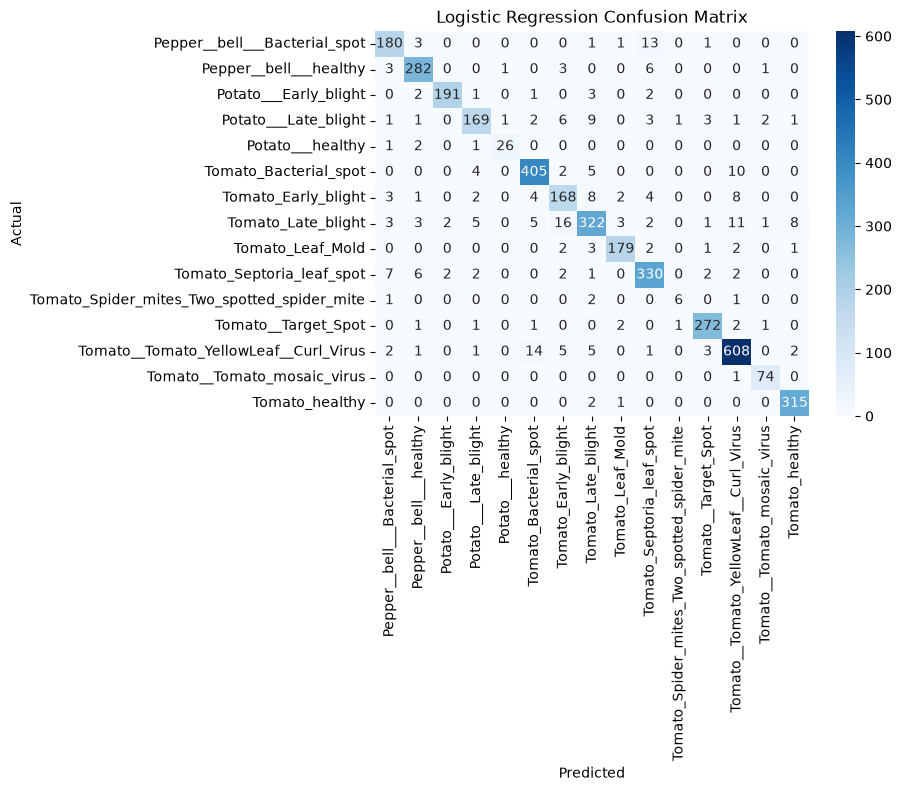

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

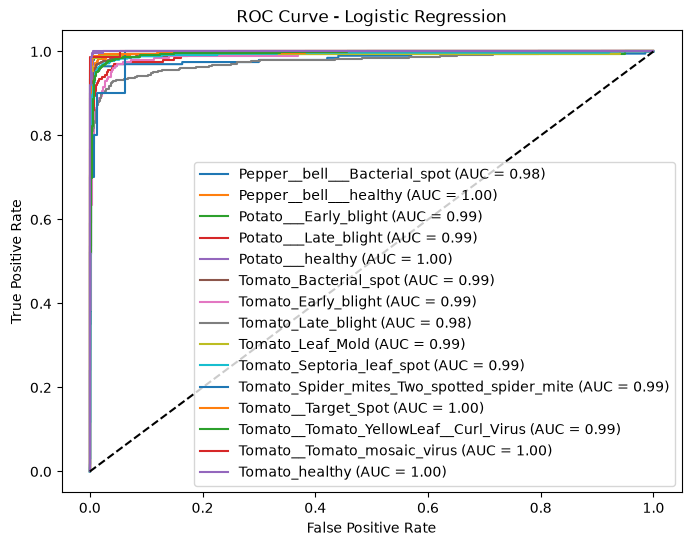

In [35]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(len(label_encoder.classes_))
)

lr_probabilities = lr_model.predict_proba(X_test_hsv)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(label_encoder.classes_):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        lr_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [36]:
%pip install tensorflow
print("okay")


Note: you may need to restart the kernel to use updated packages.
okay



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
%pip install py-cpuinfo
print("okay")

Note: you may need to restart the kernel to use updated packages.
okay



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import cpuinfo

info = cpuinfo.get_cpu_info()

print("Processor:", info.get("brand_raw"))

flags = info.get("flags", [])

print("AVX supported:", "avx" in flags)
print("AVX2 supported:", "avx2" in flags)

Processor: AMD Ryzen 5 7520U with Radeon Graphics
AVX supported: True
AVX2 supported: True


In [46]:
import tensorflow as tf
print(tf.__version__)


[TensorFlow DLL Diagnostic] Analyzing: C:\Users\YUVARANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "C:\Users\YUVARANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [40]:
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("TensorFlow version:", tf.__version__)


[TensorFlow DLL Diagnostic] Analyzing: C:\Users\YUVARANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd
[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


ImportError: Traceback (most recent call last):
  File "C:\Users\YUVARANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [39]:
X_train_dl = preprocess_input(X_train.astype("float32"))
X_test_dl = preprocess_input(X_test.astype("float32"))

print("Deep learning data prepared")

NameError: name 'preprocess_input' is not defined

In [1]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully")

NameError: name 'MobileNetV2' is not defined

In [2]:
from tensorflow.keras import layers, models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(label_encoder.classes_), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

NameError: name 'base_model' is not defined

In [3]:
history = model.fit(
    X_train_dl,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

NameError: name 'model' is not defined

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("MobileNetV2 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("MobileNetV2 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

NameError: name 'plt' is not defined

In [6]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_history = model.fit(
    X_train_dl,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

NameError: name 'base_model' is not defined

In [7]:
mobilenet_probabilities = model.predict(X_test_dl)

mobilenet_predictions = np.argmax(
    mobilenet_probabilities,
    axis=1
)

print("Predictions completed")

NameError: name 'model' is not defined

In [8]:
mobilenet_accuracy = accuracy_score(
    y_test,
    mobilenet_predictions
)

print("MobileNetV2 Accuracy:", mobilenet_accuracy * 100, "%")

NameError: name 'accuracy_score' is not defined

In [9]:
print(classification_report(
    y_test,
    mobilenet_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))

NameError: name 'classification_report' is not defined

In [10]:
cm = confusion_matrix(y_test, mobilenet_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

NameError: name 'confusion_matrix' is not defined

In [11]:
for layer in base_model.layers[::-1]:
    if len(layer.output.shape) == 4:
        print("Last convolution layer:", layer.name)
        break

NameError: name 'base_model' is not defined

In [12]:
last_conv_layer_name = layer.name

def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            base_model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        class_index = tf.argmax(predictions[0])
        loss = predictions[:, class_index]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

NameError: name 'layer' is not defined

In [13]:
sample_image = X_test[0]

input_image = np.expand_dims(
    preprocess_input(sample_image.astype("float32")),
    axis=0
)

heatmap = make_gradcam_heatmap(
    input_image,
    model,
    base_model,
    last_conv_layer_name
)

heatmap = cv2.resize(heatmap, (224, 224))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Leaf Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sample_image)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

NameError: name 'X_test' is not defined

In [14]:
CONFIDENCE_THRESHOLD = 0.70

print("Confidence threshold:", CONFIDENCE_THRESHOLD)

Confidence threshold: 0.7


In [15]:
def predict_leaf(image_path):

    img = cv2.imread(image_path)

    if img is None:
        print("Image could not be loaded")
        return

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))

    input_img = preprocess_input(
        np.expand_dims(img.astype("float32"), axis=0)
    )

    probabilities = model.predict(input_img, verbose=0)[0]

    predicted_index = np.argmax(probabilities)
    confidence = probabilities[predicted_index]

    if confidence < CONFIDENCE_THRESHOLD:
        print("Prediction: Uncertain - Please check the leaf image")
    else:
        print("Predicted Disease:", label_encoder.classes_[predicted_index])

    print("Confidence:", round(float(confidence) * 100, 2), "%")

    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [16]:
model.save("plant_leaf_disease_model.keras")

print("MobileNetV2 model saved")

NameError: name 'model' is not defined

In [17]:
import joblib

joblib.dump(lr_model, "leaf_logistic_regression.pkl")

joblib.dump(label_encoder, "leaf_label_encoder.pkl")

print("Logistic Regression model saved")

NameError: name 'lr_model' is not defined

In [18]:
comparison = pd.DataFrame({
    "Model": ["HSV + Logistic Regression", "MobileNetV2"],
    "Accuracy": [lr_accuracy * 100, mobilenet_accuracy * 100]
})

print(comparison)

comparison.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.show()

NameError: name 'pd' is not defined